# EMQA_L1_separation_2024

**Case study: market separation in summer 2024**

Energy Markets Quantitative Analysis (EMQA), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L1/EMQA_L1_separation_2024/EMQA_L1_separation_2024.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Daily base day-ahead prices in Romania, Bulgaria, Hungary and Germany-Luxembourg from June to September 2024, and hourly prices on 16 July 2024: in July 2024 Romania paid about twice the German price.

**Data:** 2024-06-01 to 2024-09-30 daily (left); 2024-07-16 hourly (right). **Source:** energy-charts.info (Fraunhofer ISE); prices from the exchanges OPCOM (RO), IBEX (BG), HUPX (HU), EPEX SPOT (DE-LU), via ENTSO-E.

The numbers printed below are those on the slide; the tag `[key]` is their name in `lectures/L1/L1_numbers.json`.

In [2]:
import json
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per bidding zone
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZONES = ['RO', 'BG', 'HU', 'DE_LU']
ZONE_NAME = {'RO': 'Romania (OPCOM PZU)', 'BG': 'Bulgaria (IBEX)', 'HU': 'Hungary (HUPX)', 'DE_LU': 'Germany-Luxembourg'}
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
MON1 = ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D']


def legend_bottom(fig, ncol=4, y=0.0):
    """One legend centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l_ in zip(*ax.get_legend_handles_labels()):
            if l_ not in labels:
                handles.append(h)
                labels.append(l_)
    if handles:
        fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
                   handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Round as on the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')


def show(key, label, value):
    """Print a number of the slide; [key] = its name in lectures/L1/L1_numbers.json."""
    print(f'{label} = {value}   [{key}]')

## Data
Real series from the course repository (see `data/SOURCES.md`), cut at the last complete month; missing values stay missing.

In [3]:
# data cut-off: last complete calendar month common to the Romanian prices and the generation data
_p = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')['RO']
_g = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', usecols=['date_cet', 'hydro_run_of_river'],
                 parse_dates=['date_cet']).set_index('date_cet')['hydro_run_of_river']
_last = min(_p.dropna().index.max(), _g.dropna().index.max())
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
END_UTC = (END + pd.Timedelta(days=1)).tz_localize('Europe/Brussels').tz_convert('UTC')   # end of the CET day, in UTC
Y = END.year
print('data cut-off:', END.date())

# daily base prices (mean of all market time units of the CET/CEST day), EUR/MWh
P = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet').loc[:END]
# hourly day-ahead prices (15-min prices averaged to the hour from Oct 2025), CET/CEST clock
H = pd.read_csv(DATA + 'power_da_prices_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
H.index = H.index.tz_convert('Europe/Brussels')
H = H.loc[:str(END.date())]

data cut-off: 2026-10-31


## Computation

In [4]:
jul = P.loc['2024-07', ZONES].mean()
g16 = P.loc['2024-07-16', ZONES]
hd16 = H.loc['2024-07-16', ZONES]                               # hourly, 16 July 2024
for z in ZONES:
    show(f'sep.jul.{z}', f'July 2024 mean, {z}, EUR/MWh', fl(jul[z], 2))
show('sep.d16_gap', '16 Jul daily base, RO - DE-LU, EUR/MWh', fl(g16['RO'] - g16['DE_LU'], 2))
show('sep.d16_ro_max', '16 Jul, highest RO hour, EUR/MWh', fl(hd16['RO'].max(), 2))
show('sep.d16_ro_max_h', '16 Jul, hour of the RO maximum (CEST)', int(hd16['RO'].idxmax().hour))
show('sep.d16_de_min', '16 Jul, lowest DE-LU hour, EUR/MWh', fl(hd16['DE_LU'].min(), 2))
show('sep.d16_de_min_h', '16 Jul, hour of the DE-LU minimum (CEST)', int(hd16['DE_LU'].idxmin().hour))

July 2024 mean, RO, EUR/MWh = 145.14   [sep.jul.RO]
July 2024 mean, BG, EUR/MWh = 136.47   [sep.jul.BG]
July 2024 mean, HU, EUR/MWh = 135.54   [sep.jul.HU]
July 2024 mean, DE_LU, EUR/MWh = 67.7   [sep.jul.DE_LU]
16 Jul daily base, RO - DE-LU, EUR/MWh = 162.87   [sep.d16_gap]
16 Jul, highest RO hour, EUR/MWh = 801.62   [sep.d16_ro_max]
16 Jul, hour of the RO maximum (CEST) = 20   [sep.d16_ro_max_h]
16 Jul, lowest DE-LU hour, EUR/MWh = -11.48   [sep.d16_de_min]
16 Jul, hour of the DE-LU minimum (CEST) = 14   [sep.d16_de_min_h]


## Chart

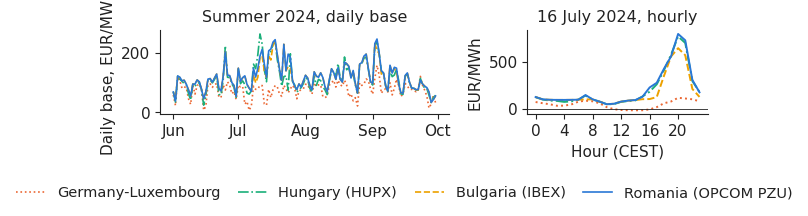

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.2), gridspec_kw={'width_ratios': [1.6, 1]})
ss = P.loc['2024-06-01':'2024-09-30', ZONES]
for z in ['DE_LU', 'HU', 'BG', 'RO']:
    axs[0].plot(ss.index, ss[z], color=PAL[z], ls=ZONE_LS[z], lw=1.2, label=ZONE_NAME[z])
    axs[1].plot(hd16.index.hour, hd16[z], color=PAL[z], ls=ZONE_LS[z], lw=1.4)
axs[0].set_ylabel('Daily base, EUR/MWh')
axs[0].xaxis.set_major_locator(mdates.MonthLocator())
axs[0].xaxis.set_major_formatter(mdates.DateFormatter('%b'))
axs[0].set_title('Summer 2024, daily base')
axs[1].axhline(0, color='#222222', lw=0.6)
axs[1].set_xlabel('Hour (CEST)')
axs[1].set_ylabel('EUR/MWh')
axs[1].set_xticks(range(0, 24, 4))
axs[1].set_title('16 July 2024, hourly')
legend_bottom(fig, ncol=4)
fig.tight_layout(rect=(0, 0.17, 1, 1))
plt.savefig('separation_2024.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()